# Partie 1 : Classification d'images (MNIST Dataset)

## Préparation des données & CNN from Scratch

In [1]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt

# 1. Vérification du matériel GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Utilisation du matériel : {device}")
if torch.cuda.is_available():
    print(f"Nombre de GPUs disponibles : {torch.cuda.device_count()}")
    print(f"Modèle GPU : {torch.cuda.get_device_name(0)}")

# 2. Prétraitement et Chargement des données MNIST
# Conversion des images PIL en Tenseurs PyTorch et Normalisation (Moyenne=0.1307, Écart-type=0.3081 pour MNIST)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Chargement automatique ou lecture depuis les données rattachées
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=2)

print(f"Taille du jeu d'entraînement : {len(train_dataset)} images")
print(f"Taille du jeu de test : {len(test_dataset)} images")

# 3. Définition de l'architecture CNN Custom
class CustomCNN(nn.Module):
    def __init__(self):
        super(CustomCNN, self).__init__()
        # Bloc Convolutionnel 1 : Entrée (1, 28, 28) -> Sortie (32, 28, 28) -> MaxPool (32, 14, 14)
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Bloc Convolutionnel 2 : Entrée (32, 14, 14) -> Sortie (64, 14, 14) -> MaxPool (64, 7, 7)
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Classifieur : Flatten -> Linear (64 * 7 * 7 = 3136) -> 128 -> 10 classes
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.classifier(x)
        return x

# Instanciation du modèle et passage sur GPU
model_cnn = CustomCNN()

# Si plusieurs GPU T4 sont disponibles, on active la parallélisation
if torch.cuda.device_count() > 1:
    print(f"Parallélisation activée sur {torch.cuda.device_count()} GPUs avec DataParallel.")
    model_cnn = nn.DataParallel(model_cnn)

model_cnn = model_cnn.to(device)

print("\n--- Architecture du CNN Custom ---")
print(model_cnn)

Utilisation du matériel : cuda
Nombre de GPUs disponibles : 2
Modèle GPU : Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 60.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.69MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.49MB/s]


Taille du jeu d'entraînement : 60000 images
Taille du jeu de test : 10000 images
Parallélisation activée sur 2 GPUs avec DataParallel.

--- Architecture du CNN Custom ---
DataParallel(
  (module): CustomCNN(
    (conv1): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (classifier): Sequential(
      (0): Flatten(start_dim=1, end_dim=-1)
      (1): Linear(in_features=3136, out_features=128, bias=True)
      (2): ReLU()
      (3): Dropout(p=0.25, inp

## Boucle d'entraînement et d'évaluation avec mesure du temps (GPU)

In [2]:
# Function d'entraînement et de mesure des performances
def train_and_evaluate_vision_model(model, train_loader, test_loader, epochs=10, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}
    
    start_time = time.time()
    
    for epoch in range(epochs):
        # Entraînement
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = correct / total
        
        # Évaluation
        model.eval()
        running_test_loss, correct_test, total_test = 0.0, 0, 0
        
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                running_test_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs.data, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()
                
        epoch_test_loss = running_test_loss / len(test_loader.dataset)
        epoch_test_acc = correct_test / total_test
        
        history['train_loss'].append(epoch_train_loss)
        history['test_loss'].append(epoch_test_loss)
        history['train_acc'].append(epoch_train_acc)
        history['test_acc'].append(epoch_test_acc)
        
        print(f"Époque {epoch+1:02d}/{epochs:02d} | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc*100:.2f}% | Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc*100:.2f}%")
        
    execution_time = time.time() - start_time
    print(f"\nTemps d'entraînement total sur GPU : {execution_time:.2f} secondes")
    
    return history, execution_time

# Lancement de l'entraînement
history_cnn, cnn_train_time = train_and_evaluate_vision_model(model_cnn, train_loader, test_loader, epochs=10)

Époque 01/10 | Train Loss: 0.1599 | Train Acc: 95.26% | Test Loss: 0.0501 | Test Acc: 98.27%
Époque 02/10 | Train Loss: 0.0573 | Train Acc: 98.25% | Test Loss: 0.0356 | Test Acc: 98.81%
Époque 03/10 | Train Loss: 0.0451 | Train Acc: 98.60% | Test Loss: 0.0384 | Test Acc: 98.76%
Époque 04/10 | Train Loss: 0.0375 | Train Acc: 98.80% | Test Loss: 0.0288 | Test Acc: 99.14%
Époque 05/10 | Train Loss: 0.0323 | Train Acc: 98.97% | Test Loss: 0.0297 | Test Acc: 99.03%
Époque 06/10 | Train Loss: 0.0281 | Train Acc: 99.11% | Test Loss: 0.0258 | Test Acc: 99.17%
Époque 07/10 | Train Loss: 0.0252 | Train Acc: 99.17% | Test Loss: 0.0273 | Test Acc: 99.16%
Époque 08/10 | Train Loss: 0.0206 | Train Acc: 99.32% | Test Loss: 0.0346 | Test Acc: 98.99%
Époque 09/10 | Train Loss: 0.0207 | Train Acc: 99.34% | Test Loss: 0.0331 | Test Acc: 99.09%
Époque 10/10 | Train Loss: 0.0179 | Train Acc: 99.43% | Test Loss: 0.0356 | Test Acc: 98.97%

Temps d'entraînement total sur GPU : 132.16 secondes


### visualiation des courbes Loss et Accuracy pour le CNN Custom

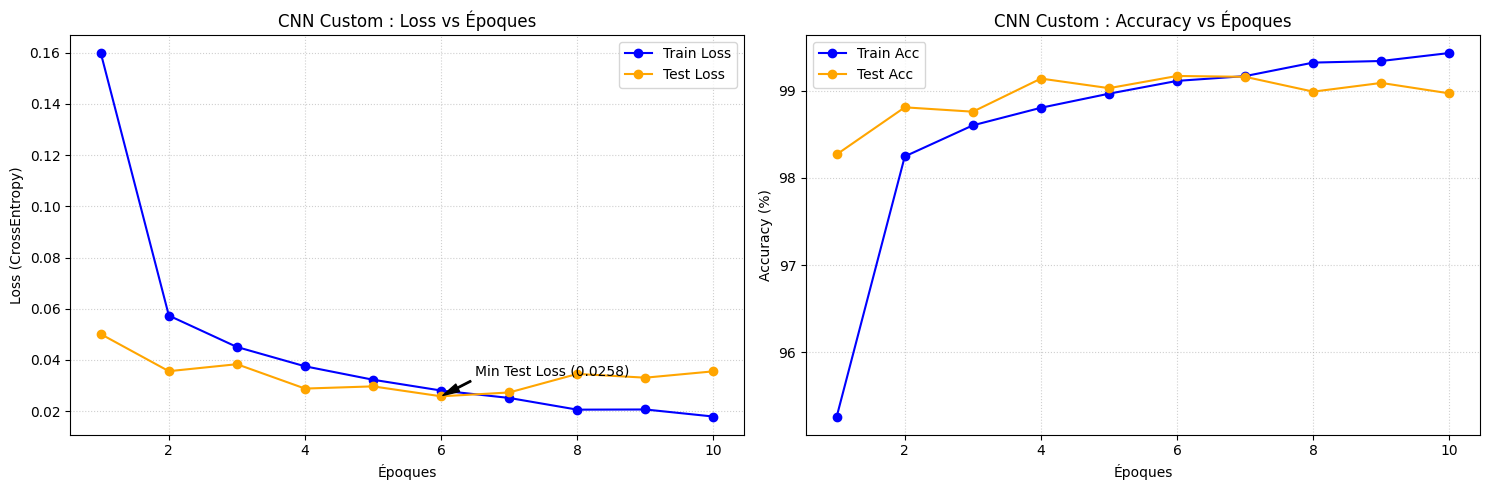

In [3]:
import matplotlib.pyplot as plt

# Tracé des courbes Loss et Accuracy pour le CNN Custom
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Graphique Loss (Train vs Test)
axes[0].plot(range(1, 11), history_cnn['train_loss'], label='Train Loss', color='blue', marker='o')
axes[0].plot(range(1, 11), history_cnn['test_loss'], label='Test Loss', color='orange', marker='o')
axes[0].set_title('CNN Custom : Loss vs Époques')
axes[0].set_xlabel('Époques')
axes[0].set_ylabel('Loss (CrossEntropy)')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Annotation de l'époque optimale
min_loss_epoch = history_cnn['test_loss'].index(min(history_cnn['test_loss'])) + 1
min_loss_val = min(history_cnn['test_loss'])
axes[0].annotate(f'Min Test Loss ({min_loss_val:.4f})', 
                 xy=(min_loss_epoch, min_loss_val), 
                 xytext=(min_loss_epoch + 0.5, min_loss_val + 0.008),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

# 2. Graphique Accuracy (Train vs Test)
axes[1].plot(range(1, 11), [acc * 100 for acc in history_cnn['train_acc']], label='Train Acc', color='blue', marker='o')
axes[1].plot(range(1, 11), [acc * 100 for acc in history_cnn['test_acc']], label='Test Acc', color='orange', marker='o')
axes[1].set_title('CNN Custom : Accuracy vs Époques')
axes[1].set_xlabel('Époques')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Transfer Learning / Fine-Tuning avec AlexNet et VGG16.

In [4]:
import torchvision.models as models

# 1. Pipeline de transformation pour ImageNet (1 -> 3 canaux, Resize 224x224, Normalisation ImageNet)
transform_imagenet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),  # Duplication du canal gris vers 3 canaux RGB
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Chargement des datasets MNIST ré-échantillonnés
train_dataset_224 = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform_imagenet)
test_dataset_224 = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform_imagenet)

# Utilisation d'un batch_size de 64 pour éviter de saturer la mémoire VRAM GPU
train_loader_224 = DataLoader(train_dataset_224, batch_size=64, shuffle=True, num_workers=2)
test_loader_224 = DataLoader(test_dataset_224, batch_size=64, shuffle=False, num_workers=2)


# --- A. FINE-TUNING ALEXNET ---
print("==========================================")
print(" 1. FINE-TUNING ALEXNET (Pre-trained on ImageNet)")
print("==========================================")

alexnet = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)

# Modification de la dernière couche linéaire du classifieur pour 10 classes
alexnet.classifier[6] = nn.Linear(alexnet.classifier[6].in_features, 10)

if torch.cuda.device_count() > 1:
    alexnet = nn.DataParallel(alexnet)
alexnet = alexnet.to(device)

# Entraînement d'AlexNet sur 3 époques (suffisant car les caractéristiques sont déjà pré-apprises)
history_alexnet, alexnet_time = train_and_evaluate_vision_model(
    alexnet, train_loader_224, test_loader_224, epochs=3, lr=0.0001
)


# --- B. FINE-TUNING VGG16 ---
print("\n==========================================")
print(" 2. FINE-TUNING VGG16 (Pre-trained on ImageNet)")
print("==========================================")

vgg16 = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

# Modification de la dernière couche linéaire du classifieur pour 10 classes
vgg16.classifier[6] = nn.Linear(vgg16.classifier[6].in_features, 10)

if torch.cuda.device_count() > 1:
    vgg16 = nn.DataParallel(vgg16)
vgg16 = vgg16.to(device)

# Entraînement de VGG16 sur 3 époques
history_vgg16, vgg16_time = train_and_evaluate_vision_model(
    vgg16, train_loader_224, test_loader_224, epochs=3, lr=0.0001
)

 1. FINE-TUNING ALEXNET (Pre-trained on ImageNet)
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 190MB/s]  


Époque 01/03 | Train Loss: 0.0861 | Train Acc: 97.42% | Test Loss: 0.0313 | Test Acc: 99.14%
Époque 02/03 | Train Loss: 0.0299 | Train Acc: 99.13% | Test Loss: 0.0223 | Test Acc: 99.34%
Époque 03/03 | Train Loss: 0.0245 | Train Acc: 99.28% | Test Loss: 0.0377 | Test Acc: 98.85%

Temps d'entraînement total sur GPU : 353.20 secondes

 2. FINE-TUNING VGG16 (Pre-trained on ImageNet)
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 208MB/s]  


Époque 01/03 | Train Loss: 0.0726 | Train Acc: 97.80% | Test Loss: 0.0333 | Test Acc: 99.01%
Époque 02/03 | Train Loss: 0.0279 | Train Acc: 99.19% | Test Loss: 0.0204 | Test Acc: 99.47%
Époque 03/03 | Train Loss: 0.0203 | Train Acc: 99.39% | Test Loss: 0.0158 | Test Acc: 99.53%

Temps d'entraînement total sur GPU : 1819.69 secondes


### Tableau & Graphique comparatif de la Classification (CNN Custom vs AlexNet vs VGG16)

TABLEAU COMPARATIF DES CLASSIFIEURS VISION :
                   Modèle  Test Accuracy (%)  Min Test Loss  Temps (secondes)  Temps (minutes) Taille Image Entrée
Custom CNN (From Scratch)              98.97       0.025816        132.159407         2.202657   28x28 (Grayscale)
     AlexNet (Fine-Tuned)              98.85       0.022289        353.200125         5.886669       224x224 (RGB)


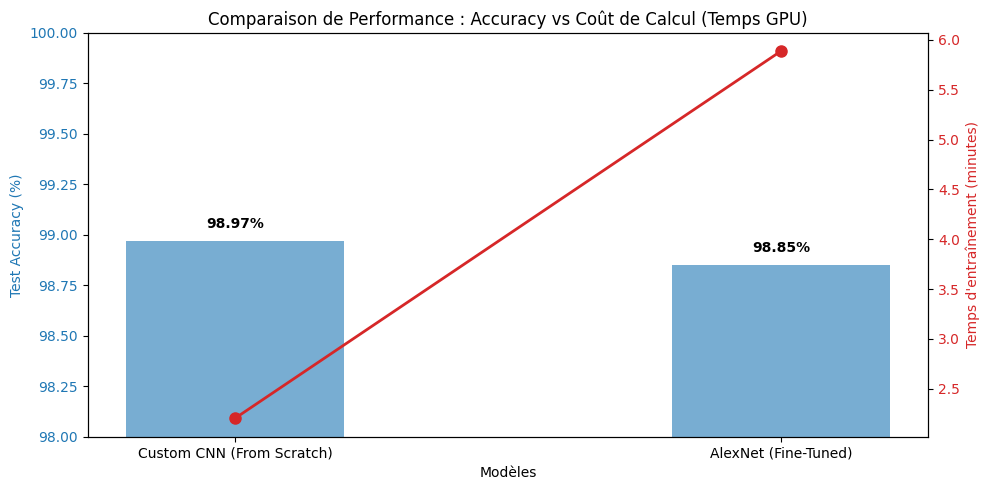

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Création du DataFrame de comparaison
# Remarque : Ajoutez VGG16 si vous avez exécuté VGG16
data_comparison = {
    'Modèle': ['Custom CNN (From Scratch)', 'AlexNet (Fine-Tuned)'],
    'Test Accuracy (%)': [history_cnn['test_acc'][-1] * 100, history_alexnet['test_acc'][-1] * 100],
    'Min Test Loss': [min(history_cnn['test_loss']), min(history_alexnet['test_loss'])],
    'Temps (secondes)': [cnn_train_time, alexnet_time],
    'Temps (minutes)': [cnn_train_time / 60, alexnet_time / 60],
    'Taille Image Entrée': ['28x28 (Grayscale)', '224x224 (RGB)']
}

df_comp = pd.DataFrame(data_comparison)
print("==========================================")
print("TABLEAU COMPARATIF DES CLASSIFIEURS VISION :")
print("==========================================")
print(df_comp.to_string(index=False))

# 2. Graphique comparatif : Accuracy vs Temps d'entraînement
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Modèles')
ax1.set_ylabel('Test Accuracy (%)', color=color)
bars = ax1.bar(df_comp['Modèle'], df_comp['Test Accuracy (%)'], color=color, alpha=0.6, width=0.4)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(98.0, 100.0)

# Ajout des valeurs d'accuracy sur les barres
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.05, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

# Second axe Y pour le temps d'entraînement
ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Temps d\'entraînement (minutes)', color=color)
lines = ax2.plot(df_comp['Modèle'], df_comp['Temps (minutes)'], color=color, marker='o', linewidth=2, markersize=8)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Comparaison de Performance : Accuracy vs Coût de Calcul (Temps GPU)')
fig.tight_layout()
plt.show()

# Partie 2 : Détection d'Objets avec Faster R-CNN.

In [7]:
import os
import time
import zipfile
import urllib.request
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import torchvision.transforms as T
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. Configuration du matériel GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 2. Dataset Penn-Fudan Pedestrian Corrigé
class PennFudanDataset(torch.utils.data.Dataset):
    def __init__(self, root, transforms=None):
        self.root = root
        self.transforms = transforms
        self.imgs = list(sorted(os.listdir(os.path.join(root, "PNGImages"))))
        self.masks = list(sorted(os.listdir(os.path.join(root, "PedMasks"))))

    def __getitem__(self, idx):
        img_path = os.path.join(self.root, "PNGImages", self.imgs[idx])
        mask_path = os.path.join(self.root, "PedMasks", self.masks[idx])
        
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)
        
        # CORRECTION ICI : Conversion de la PIL Image en NumPy array avant Tensor
        mask = np.array(mask)
        mask = torch.as_tensor(mask, dtype=torch.uint8)

        # Extraire les boîtes englobantes depuis le masque
        obj_ids = torch.unique(mask)
        obj_ids = obj_ids[1:]  # Ignorer le fond (ID 0)
        
        masks = mask == obj_ids[:, None, None]
        num_objs = len(obj_ids)
        boxes = []
        
        for i in range(num_objs):
            pos = torch.where(masks[i])
            xmin = torch.min(pos[1]).item()
            xmax = torch.max(pos[1]).item()
            ymin = torch.min(pos[0]).item()
            ymax = torch.max(pos[0]).item()
            boxes.append([xmin, ymin, xmax, ymax])

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.ones((num_objs,), dtype=torch.int64) # Class 1 = Piéton

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx])
        }

        if self.transforms is not None:
            img = self.transforms(img)

        return img, target

    def __len__(self):
        return len(self.imgs)

def get_transform():
    return T.Compose([T.ToTensor()])

# Telechargement si besoin
dataset_dir = "PennFudanPed"
if not os.path.exists(dataset_dir):
    print("Téléchargement du dataset Penn-Fudan Pedestrian...")
    url = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
    urllib.request.urlretrieve(url, "PennFudanPed.zip")
    with zipfile.ZipFile("PennFudanPed.zip", 'r') as zip_ref:
        zip_ref.extractall(".")

dataset = PennFudanDataset('PennFudanPed', get_transform())
dataset_test = PennFudanDataset('PennFudanPed', get_transform())

# Split Train / Test
torch.manual_seed(42)
indices = torch.randperm(len(dataset)).tolist()
train_dataset_rcnn = torch.utils.data.Subset(dataset, indices[:-50])
test_dataset_rcnn = torch.utils.data.Subset(dataset_test, indices[-50:])

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader_rcnn = DataLoader(train_dataset_rcnn, batch_size=2, shuffle=True, collate_fn=collate_fn)
test_loader_rcnn = DataLoader(test_dataset_rcnn, batch_size=1, shuffle=False, collate_fn=collate_fn)

# 3. Chargement et ré-adaptation de Faster R-CNN
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model_rcnn = fasterrcnn_resnet50_fpn(weights=weights)

in_features = model_rcnn.roi_heads.box_predictor.cls_score.in_features
model_rcnn.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
model_rcnn = model_rcnn.to(device)

# 4. Entraînement
params = [p for p in model_rcnn.parameters() if p.requires_grad]
optimizer_rcnn = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)

epochs_rcnn = 3
print("--- Début de l'entraînement de Faster R-CNN ---")
start_time_rcnn = time.time()

for epoch in range(epochs_rcnn):
    model_rcnn.train()
    epoch_loss = 0
    for images, targets in train_loader_rcnn:
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model_rcnn(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer_rcnn.zero_grad()
        losses.backward()
        optimizer_rcnn.step()

        epoch_loss += losses.item()

    print(f"Époque {epoch+1:02d}/{epochs_rcnn:02d} | Faster R-CNN Loss: {epoch_loss/len(train_loader_rcnn):.4f}")

print(f"Temps d'entraînement total : {time.time() - start_time_rcnn:.2f} secondes")


--- Début de l'entraînement de Faster R-CNN ---
Époque 01/03 | Faster R-CNN Loss: 0.2757
Époque 02/03 | Faster R-CNN Loss: 0.1196
Époque 03/03 | Faster R-CNN Loss: 0.0992
Temps d'entraînement total : 106.17 secondes


## Inférence et Visualisation des Boîtes Englobantes (Bounding Boxes)

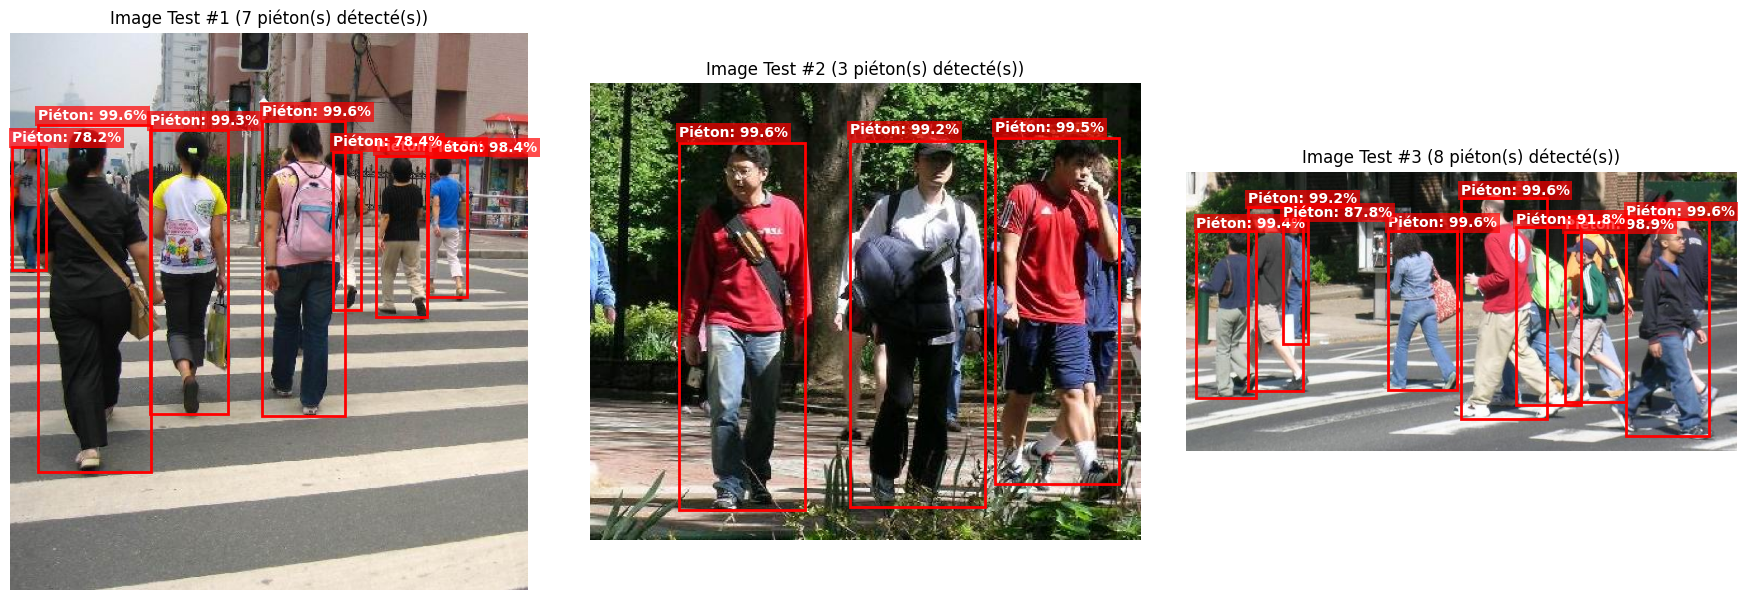

In [8]:
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# 1. Mettre le modèle en mode évaluation
model_rcnn.eval()

# 2. Fonction de visualisation des détections
def visualize_predictions(model, dataset, num_images=3, score_threshold=0.7):
    fig, axes = plt.subplots(1, num_images, figsize=(6 * num_images, 6))
    if num_images == 1:
        axes = [axes]
        
    for i in range(num_images):
        # Récupération d'une image du jeu de test
        img, target = dataset[i]
        
        # Passage sur GPU et inférence sans calcul de gradients
        with torch.no_grad():
            prediction = model([img.to(device)])
        
        # Conversion du tenseur d'image en format NumPy (C, H, W -> H, W, C)
        img_np = img.permute(1, 2, 0).cpu().numpy()
        
        # Extraire les boîtes englobantes et scores
        boxes = prediction[0]['boxes'].cpu().numpy()
        scores = prediction[0]['scores'].cpu().numpy()
        
        # Affichage de l'image
        ax = axes[i]
        ax.imshow(img_np)
        
        # Tracer les boîtes ayant un score supérieur au seuil de confiance
        num_detected = 0
        for box, score in zip(boxes, scores):
            if score >= score_threshold:
                num_detected += 1
                xmin, ymin, xmax, ymax = box
                width, height = xmax - xmin, ymax - ymin
                
                # Dessiner le rectangle de la Bounding Box
                rect = patches.Rectangle(
                    (xmin, ymin), width, height, 
                    linewidth=2, edgecolor='red', facecolor='none'
                )
                ax.add_patch(rect)
                
                # Afficher le label et le score de confiance
                ax.text(
                    xmin, ymin - 5, f'Piéton: {score*100:.1f}%', 
                    color='white', fontsize=10, fontweight='bold',
                    bbox=dict(facecolor='red', alpha=0.7, edgecolor='none', pad=2)
                )
                
        ax.set_title(f"Image Test #{i+1} ({num_detected} piéton(s) détecté(s))")
        ax.axis('off')
        
    plt.tight_layout()
    plt.show()

# 3. Lancement de la visualisation sur 3 images de test
visualize_predictions(model_rcnn, test_dataset_rcnn, num_images=3, score_threshold=0.7)